# JEPA-VLM · Object hallucination · Yes/No test + DLA cache

Model: frozen I-JEPA ViT-H/16 -> trained MLP projector (`best.pt`, val 1.8704) -> frozen 4-bit Vicuna-7B-v1.5.
Sequence layout is the same as in projector training: `[784 image tokens][BOS][prompt text]`.

1. Setup + load model (projector from the checkpoint dataset)
2. Load **object-hallucination yes/no** questions (POPE / AMBER, found in `vlm-questions`)
3. **Gallery test**: 12 images with question, ground truth and the model's Yes/No answer
4. Quick accuracy check + prompt comparison (pick the prompt that behaves best)
5. **DLA caching in Rohan's `dla-llava` format** (`embed`, `attn[layer, head]`, `mlp[layer]`, `resid_dot`, `rms`, `logit_diff`, `answer_text` + question metadata), 200 per batch file, Kaggle upload + resume
6. Verification (same checks as his collect notebook)

Settings: GPU T4 x2, Internet On. Run the install cell, **restart the session**, then run everything from the config cell.

In [1]:
# 0. INSTALL (run once, then restart the session and skip this cell)
!pip install -q transformers==5.16.1 accelerate==1.14.0 bitsandbytes==0.50.2 pillow==12.3.0 sentencepiece

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 48.4 MB/s eta 0:00:00:00:0100:01


In [2]:
# 1. CONFIG
import os, re, json, glob, math, time, random, shutil, subprocess
from collections import Counter

USERNAME      = "ponishbhatia2"
CKPT_DIR      = f"/kaggle/input/datasets/{USERNAME}/jepa-projector-fixed-ckpts"
CKPT_NAME     = "best.pt"                     # best.pt = val 1.8704 (final.pt is overfit: 1.8942)
LLM_PATH      = "lmsys/vicuna-7b-v1.5"
VIT_ID        = "facebook/ijepa_vith16_1k"

QUESTIONS_JSON = f"/kaggle/input/datasets/{USERNAME}/vlm-questions/all_questions.json"   # same file Rohan used (17492 questions, version 2)
IMG_DIR        = "/kaggle/input/datasets/nadaibrahim/coco2014/val2014/val2014"             # POPE images (object questions are all POPE)

HALLUC_TYPE   = "object"                      # filter: hallucination_type == "object" and answer_format == "yes_no" (3000 questions, as in Rohan's run)
MAX_SAMPLES   = None                          # None = all; or an int for a smaller test run
SEED          = 0

PROMPT_KEY    = "vicuna"                      # one of PROMPTS below; compare in section 4 and change if another is better
PROMPTS = {
    "vicuna": "A chat between a curious human and an artificial intelligence assistant. USER: {q} Answer with Yes or No. ASSISTANT:",
    "plain":  "Question: {q} Answer with yes or no.\nAnswer:",
    "bare":   "{q} Please answer yes or no.\nAnswer:",
}

N_GALLERY     = 12
N_QUICK_EVAL  = 200

# DLA caching: same layout as Rohan's dla-llava dataset ({type}_batch_{i}.pt, 200 entries per file, dla_meta.json)
BATCH_SAVE_SIZE   = 200
DLA_DIR           = "/kaggle/working/dla_jepa"
DATASET_SLUG      = "dla-jepa-vicuna"                          # his is dla-llava; rename if you prefer
UPLOAD            = True
UPLOAD_EVERY      = 5                                          # batches between Kaggle dataset versions (a final upload always happens)
FORCE_FRESH       = False                                      # True: ignore batches already in DLA_DIR / the mounted dataset

random.seed(SEED)
os.makedirs(DLA_DIR, exist_ok=True)

In [3]:
# 2. LOAD MODELS
import numpy as np, torch, torch.nn as nn
from PIL import Image
import transformers, bitsandbytes
from transformers import LlamaTokenizer, AutoModel, AutoImageProcessor, AutoModelForCausalLM, BitsAndBytesConfig

print("transformers", transformers.__version__, "| bitsandbytes", bitsandbytes.__version__, "| torch", torch.__version__)
assert torch.cuda.is_available(), "No GPU: set Accelerator to T4 x2"
device = "cuda:0"

tokenizer = LlamaTokenizer.from_pretrained(LLM_PATH)
if tokenizer.pad_token is None: tokenizer.pad_token = tokenizer.eos_token
toks = tokenizer.convert_ids_to_tokens(tokenizer("A yellow clock that is on the floor.").input_ids)
EXPECT = ["<s>", "▁A", "▁yellow", "▁clock", "▁that", "▁is", "▁on", "▁the", "▁floor", "."]
assert toks == EXPECT, f"TOKENIZER BROKEN: {toks}"
print(type(tokenizer).__name__, "OK")

# projector checkpoint
ck_path = f"{CKPT_DIR}/{CKPT_NAME}"
if not os.path.exists(ck_path):
    alt = sorted(glob.glob(f"/kaggle/input/**/jepa-projector-fixed-ckpts/{CKPT_NAME}", recursive=True))
    assert alt, f"checkpoint not found: {ck_path}"
    ck_path = alt[-1]
ck = torch.load(ck_path, map_location="cpu", weights_only=False)
assert ck.get("meta", {}).get("tokenizer") == "LlamaTokenizer", "checkpoint was not trained with the fixed tokenizer"
print(f"loaded {ck_path} | step {ck['step']} | best val {ck.get('best')}")

image_processor = AutoImageProcessor.from_pretrained(VIT_ID)
vit = AutoModel.from_pretrained(VIT_ID).to(device).eval()
for p in vit.parameters(): p.requires_grad_(False)
vit_dtype = next(vit.parameters()).dtype

llm = AutoModelForCausalLM.from_pretrained(
    LLM_PATH, quantization_config=BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_compute_dtype=torch.float16),
    device_map={"": 0}, low_cpu_mem_usage=True).eval()
for p in llm.parameters(): p.requires_grad_(False)
LLM_DTYPE = next(llm.parameters()).dtype
H = llm.config.hidden_size
N_LAYERS = llm.config.num_hidden_layers
N_HEADS = llm.config.num_attention_heads
HEAD_DIM = H // N_HEADS
assert LLM_DTYPE == torch.float16

class MLPProjector(nn.Module):
    def __init__(self, v, l):
        super().__init__()
        self.proj = nn.Sequential(nn.Linear(v, l), nn.GELU(), nn.Linear(l, l))
    def forward(self, x): return self.proj(x)

P = MLPProjector(1280, H).to(device)
P.load_state_dict(ck["projector"]); P.eval()
for p in P.parameters(): p.requires_grad_(False)
print("vit", vit_dtype, "| llm", LLM_DTYPE, "| hidden", H, "| layers", N_LAYERS, "| heads", N_HEADS)

transformers 5.16.1 | bitsandbytes 0.50.2 | torch 2.11.0+cu128


tokenizer_config.json:   0%|          | 0.00/749 [00:00<?, ?B/s]

tokenizer.model: reconstructing file:   0%|          |  0.00B /  500kB            

tokenizer.model: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/438 [00:00<?, ?B/s]

...

model.safetensors.index.json:   0%|          | 0.00/28.1k [00:00<?, ?B/s]

Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/162 [00:00<?, ?B/s]

[transformers] The following generation flags are not valid and may be ignored: ['temperature', 'top_p']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


vit torch.float32 | llm torch.float16 | hidden 4096 | layers 32 | heads 32


In [4]:
# 3. PROMPTING + YES/NO SCORING
def toks_to_ids(cands):
    out = []
    for t in cands:
        i = tokenizer.convert_tokens_to_ids(t)
        if i is not None and i != tokenizer.unk_token_id and i not in out: out.append(i)
    return out
YES_IDS = toks_to_ids(["▁Yes", "Yes", "▁yes", "yes"])
NO_IDS  = toks_to_ids(["▁No", "No", "▁no", "no"])
YES_ID, NO_ID = YES_IDS[0], NO_IDS[0]            # "▁Yes" / "▁No": same ids Rohan used for LLaVA (shared Llama vocabulary)
assert (YES_ID, NO_ID) == (3869, 1939), (YES_ID, NO_ID)
assert tokenizer.convert_ids_to_tokens(YES_ID) == "▁Yes" and tokenizer.convert_ids_to_tokens(NO_ID) == "▁No"
print("yes ids", dict(zip(tokenizer.convert_ids_to_tokens(YES_IDS), YES_IDS)), "| no ids", dict(zip(tokenizer.convert_ids_to_tokens(NO_IDS), NO_IDS)))

def load_img(path): return Image.open(path).convert("RGB")

@torch.no_grad()
def encode_image(path):
    pv = image_processor(load_img(path), return_tensors="pt")["pixel_values"].to(device, dtype=vit_dtype)
    feats = vit(pixel_values=pv).last_hidden_state            # (1, 784, 1280)
    proj = P(feats.float())                                  # (1, 784, 4096)
    return feats, proj

@torch.no_grad()
def build_embeds(proj, question, prompt_key=None):
    # layout identical to training: [image tokens][BOS][text]
    text = PROMPTS[prompt_key or PROMPT_KEY].format(q=question.strip())
    ids = torch.tensor([tokenizer(text).input_ids], device=device)         # starts with BOS
    te = llm.get_input_embeddings()(ids).float()
    return torch.cat([proj, te], 1).to(LLM_DTYPE), ids

def score_from_logits(lg):
    lg = lg.float()
    y = torch.logsumexp(lg[YES_IDS], 0).item(); n = torch.logsumexp(lg[NO_IDS], 0).item()
    return y, n, ("yes" if y > n else "no"), 1 / (1 + math.exp(-(y - n)))

@torch.no_grad()
def answer(path, question, prompt_key=None):
    feats, proj = encode_image(path)
    emb, _ = build_embeds(proj, question, prompt_key)
    lg = llm(inputs_embeds=emb, use_cache=False, logits_to_keep=1).logits[0, -1]
    return score_from_logits(lg)

@torch.no_grad()
def generate_text(path, question, max_new=6):
    feats, proj = encode_image(path)
    emb, _ = build_embeds(proj, question)
    out = llm.generate(inputs_embeds=emb, attention_mask=torch.ones(emb.shape[:2], dtype=torch.long, device=device),
                       max_new_tokens=max_new, do_sample=False, pad_token_id=tokenizer.eos_token_id)
    return tokenizer.decode(out[0], skip_special_tokens=True).strip()

yes ids {'▁Yes': 3869, 'Yes': 8241, '▁yes': 4874, 'yes': 3582} | no ids {'▁No': 1939, 'No': 3782, '▁no': 694, 'no': 1217}


In [5]:
# 4. LOAD OBJECT-HALLUCINATION YES/NO QUESTIONS
with open(QUESTIONS_JSON) as f: all_questions = json.load(f)
assert len(all_questions) == 17492, "attach vlm-questions version 2 (17492 questions)"
print(len(all_questions), "questions | types:", dict(Counter(q["hallucination_type"] for q in all_questions)))
recs = [dict(q, gt=str(q["ground_truth_answer"]).strip().lower(), path=os.path.join(IMG_DIR, f"{q['image_id']}.jpg"))
        for q in all_questions if q["hallucination_type"] == HALLUC_TYPE and q["answer_format"] == "yes_no"]
missing = [r for r in recs if not os.path.exists(r["path"])]
print(f"{HALLUC_TYPE}: {len(recs)} yes/no questions | missing images: {len(missing)} | gt: {dict(Counter(r['gt'] for r in recs))}")
assert recs and not missing, "check IMG_DIR / question file"
if MAX_SAMPLES: recs = recs[:MAX_SAMPLES]

17492 questions | types: {'object': 3000, 'attribute': 7628, 'relation': 6864}
object: 3000 yes/no questions | missing images: 0 | gt: {'yes': 1500, 'no': 1500}


[transformers] Both `max_new_tokens` (=6) and `max_length`(=4096) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=6) and `max_length`(=4096) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=6) and `max_length`(=4096) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=6) and `max_length`(=4096) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/

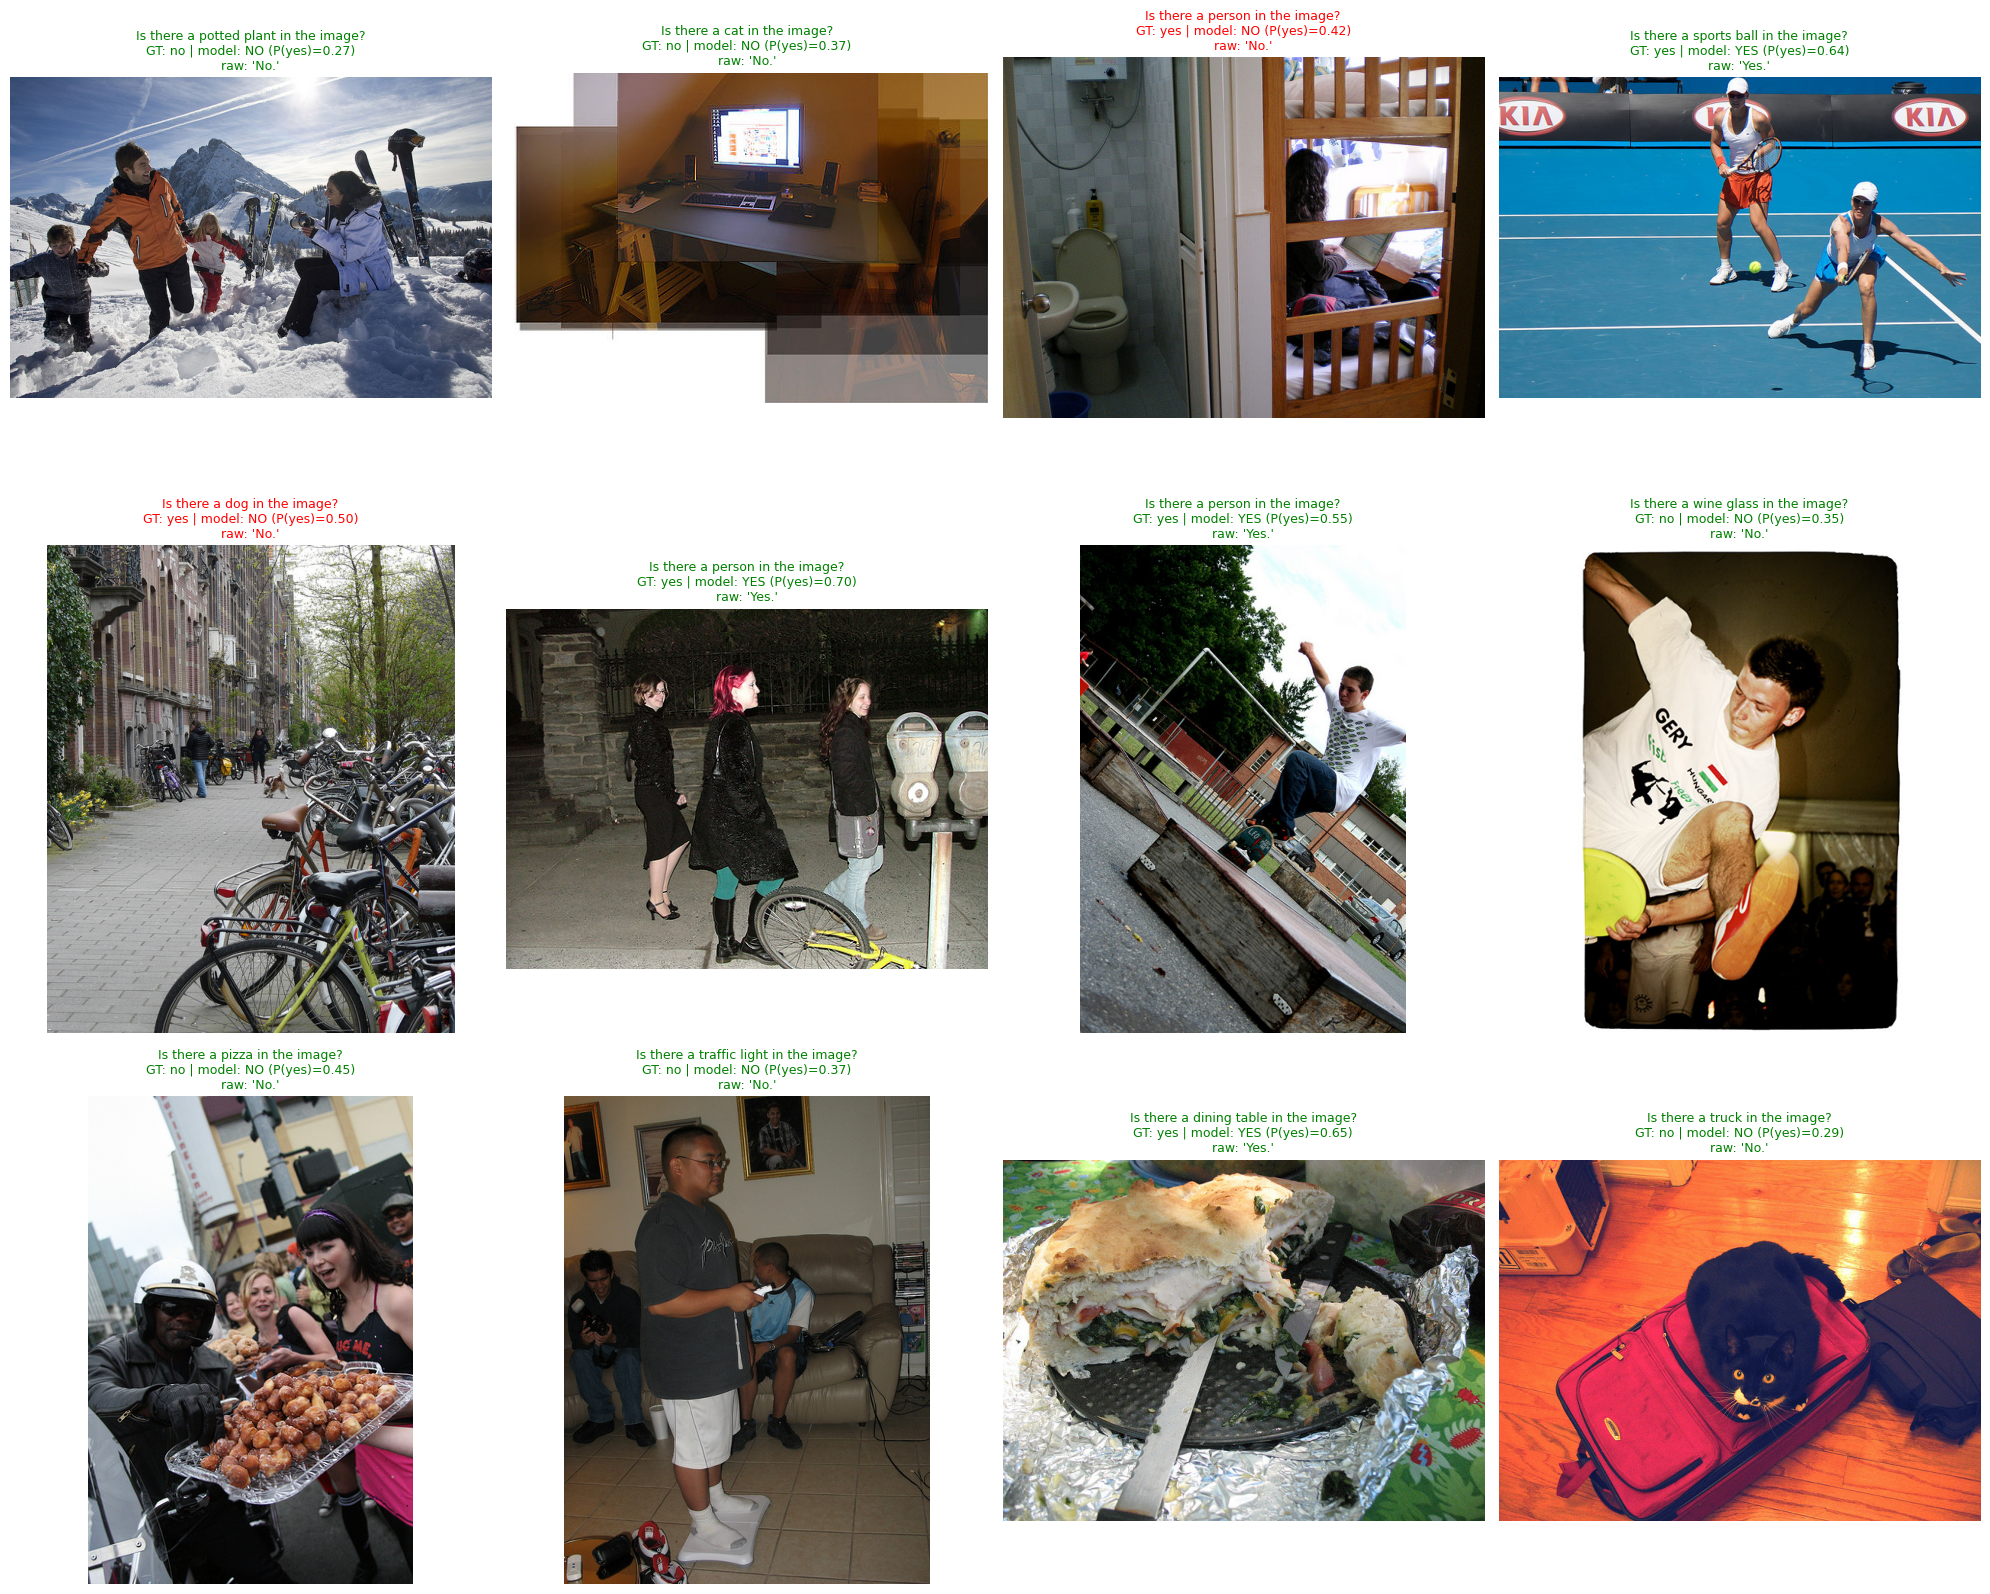

gallery accuracy 10/12


In [6]:
# 5. GALLERY TEST: image + question + model Yes/No + ground truth
import matplotlib.pyplot as plt
yes_pool = [r for r in recs if r["gt"] == "yes"]; no_pool = [r for r in recs if r["gt"] == "no"]
rng = random.Random(1)
gal = rng.sample(yes_pool, N_GALLERY // 2) + rng.sample(no_pool, N_GALLERY - N_GALLERY // 2)
rng.shuffle(gal)

cols = 4; rows_ = math.ceil(len(gal) / cols)
fig, axes = plt.subplots(rows_, cols, figsize=(5 * cols, 5.4 * rows_))
n_ok = 0
for ax, r in zip(axes.ravel(), gal):
    y, n, pred, py = answer(r["path"], r["question_text"])
    try: gen = generate_text(r["path"], r["question_text"])
    except Exception as e: gen = "(gen failed)"
    ok = pred == r["gt"]; n_ok += ok
    ax.imshow(load_img(r["path"])); ax.axis("off")
    ax.set_title(f"{r['question_text']}\nGT: {r['gt']} | model: {pred.upper()} (P(yes)={py:.2f})\nraw: {gen[:40]!r}",
                 fontsize=9, color=("green" if ok else "red"))
for ax in axes.ravel()[len(gal):]: ax.axis("off")
plt.tight_layout(); plt.show()
print(f"gallery accuracy {n_ok}/{len(gal)}")

In [7]:
# 6. QUICK EVAL + PROMPT COMPARISON (balanced sample)
try: from sklearn.metrics import roc_auc_score
except Exception: roc_auc_score = None
rng = random.Random(2)
k = N_QUICK_EVAL // 2
evalset = rng.sample(yes_pool, min(k, len(yes_pool))) + rng.sample(no_pool, min(k, len(no_pool)))

def quick_eval(prompt_key, items):
    ys, preds, gts = [], [], []
    for r in items:
        y, n, pred, py = answer(r["path"], r["question_text"], prompt_key)
        ys.append(y - n); preds.append(pred); gts.append(r["gt"])
    acc = np.mean([p == g for p, g in zip(preds, gts)])
    yes_rate = np.mean([p == "yes" for p in preds])
    auc = roc_auc_score([g == "yes" for g in gts], ys) if roc_auc_score and len(set(gts)) == 2 else float("nan")
    return acc, yes_rate, auc, len(preds)

print(f"{'prompt':8s} {'acc':>6s} {'yes-rate':>9s} {'AUROC':>6s} {'n':>5s}   (balanced set: chance acc 0.50, ideal yes-rate 0.50)")
for key in PROMPTS:
    acc, yr, auc, n = quick_eval(key, evalset)
    print(f"{key:8s} {acc:6.3f} {yr:9.3f} {auc:6.3f} {n:5d}")
print("PROMPT_KEY currently:", PROMPT_KEY, "-> change it in CONFIG (and re-run from section 3) if another prompt is clearly better")

prompt      acc  yes-rate  AUROC     n   (balanced set: chance acc 0.50, ideal yes-rate 0.50)
vicuna    0.750     0.400  0.819   200
plain     0.515     0.035  0.695   200
bare      0.500     0.010  0.621   200
PROMPT_KEY currently: vicuna -> change it in CONFIG (and re-run from section 3) if another prompt is clearly better


## vicuna: 75% accuracy on a balanced set. The yes-rate of 0.40 is close to the ideal 0.50, so there’s only a mild lean towards “No”. For a projector trained only on captions with no QA tuning, this is a real result. An AUROC of 0.82 means the image is actually driving the answer, not just a language prior.

vicuna: 75% accuracy on a balanced set. The yes-rate of 0.40 is close to the ideal 0.50, so there’s only a mild lean towards “No”. For a projector trained only on captions with no QA tuning, this is a real result. An AUROC of 0.82 means the image is actually driving the answer, not just a language prior.
plain: it says “No” to almost everything (3.5% yes), which gives chance accuracy. The 0.695 AUROC shows there is still some image signal in the Yes−No score, but the default cutoff at 0 throws it away. The prompt format is the problem here, not the image.
Caveat: n is 200, so accuracy has roughly ±3 points of noise. The gap between vicuna and plain is far larger than that.
Context: published VLMs score about 85–90% on POPE. This model uses a frozen encoder, a small MLP projector and a 4-bit LLM, so the gap is expected.

In [10]:
# 7. DLA MACHINERY (same math and hook points as Rohan's collect_llava.ipynb)
# u = ln_f.weight * (W_U[yes] - W_U[no]). embed / attn[layer, head] / mlp[layer] / resid_dot are RAW projections onto u;
# divide by rms to get logit units.  embed + sum(attn) + sum(mlp) = resid_dot,  resid_dot / rms = logit_diff.
lm_head, ln_f, layers = llm.lm_head, llm.model.norm, llm.model.layers
n_layer, n_head, head_dim = N_LAYERS, N_HEADS, HEAD_DIM
u = (ln_f.weight.float() * (lm_head.weight[YES_ID] - lm_head.weight[NO_ID]).float()).to(device)

# head_proj[l] = W_O^T.view(n_head, head_dim, hidden) @ u.  The 4-bit o_proj weight is packed, so get W_O^T by applying o_proj to the identity.
eye = torch.eye(H, dtype=LLM_DTYPE, device=device)
with torch.no_grad():
    head_proj = [(layers[l].self_attn.o_proj(eye).float() @ u).view(n_head, head_dim) for l in range(n_layer)]
del eye; torch.cuda.empty_cache()

_dla_cache = {}
def _make_attn_hook(l):
    def hook(module, args):
        z = args[0][0, -1].float().reshape(n_head, head_dim)
        _dla_cache[f"attn_{l}"] = (z * head_proj[l]).sum(-1)
    return hook
def _make_mlp_hook(l):
    def hook(module, args, output):
        o = output[0] if isinstance(output, tuple) else output
        _dla_cache[f"mlp_{l}"] = o[0, -1].float() @ u
    return hook
def _final_norm_hook(module, args):
    h = args[0][0, -1].float()
    _dla_cache["resid_dot"] = h @ u
    _dla_cache["rms"] = torch.sqrt(h.pow(2).mean() + ln_f.variance_epsilon)

_hook_handles = []
for l, layer in enumerate(layers):
    _hook_handles.append(layer.self_attn.o_proj.register_forward_pre_hook(_make_attn_hook(l)))
    _hook_handles.append(layer.mlp.register_forward_hook(_make_mlp_hook(l)))
_hook_handles.append(ln_f.register_forward_pre_hook(_final_norm_hook))
print(len(_hook_handles), "hooks registered")

@torch.no_grad()
def dla_question(image_path, question_text):
    feats, proj = encode_image(image_path)
    emb, ids = build_embeds(proj, question_text)
    _dla_cache.clear()
    last_logits = llm(inputs_embeds=emb, use_cache=False, logits_to_keep=1).logits[0, -1].float()
    y, n, pred, py = score_from_logits(last_logits)
    return {
        "embed": (emb[0, -1].float() @ u).cpu(),
        "attn": torch.stack([_dla_cache[f"attn_{l}"].cpu() for l in range(n_layer)]),   # [layer, head]
        "mlp": torch.stack([_dla_cache[f"mlp_{l}"].cpu() for l in range(n_layer)]),     # [layer]
        "resid_dot": _dla_cache["resid_dot"].cpu(),
        "rms": _dla_cache["rms"].cpu(),
        "logit_diff": (last_logits[YES_ID] - last_logits[NO_ID]).cpu(),
        "answer_text": tokenizer.decode(last_logits.argmax().item()).strip(),
        "pred": pred, "p_yes": py, "yesno_score": y - n,
    }

# sanity check on 6 samples: components must add up to the final residual and to the real logit difference
for r in recs[:6]:
    e = dla_question(r["path"], r["question_text"])
    total = e["embed"] + e["attn"].sum() + e["mlp"].sum()
    scale = e["embed"].abs() + e["attn"].abs().sum() + e["mlp"].abs().sum()
    rel = ((total - e["resid_dot"]).abs() / scale).item(); err = (total / e["rms"] - e["logit_diff"]).abs().item()
    print(f"logit diff {e['logit_diff']:+.3f} | sum of components {(total / e['rms']):+.3f} | rel err resid {rel:.5f} | abs err {err:.4f} | argmax token {e['answer_text']!r}")
    assert rel < 0.05 and err < 0.5, "DLA decomposition does not match the model: do not cache until fixed"
print("DLA decomposition OK")

65 hooks registered
logit diff +0.688 | sum of components +0.678 | rel err resid 0.00003 | abs err 0.0093 | argmax token 'Yes'
logit diff -0.703 | sum of components -0.700 | rel err resid 0.00005 | abs err 0.0027 | argmax token 'No'
logit diff +0.250 | sum of components +0.254 | rel err resid 0.00002 | abs err 0.0041 | argmax token 'Yes'
logit diff -0.375 | sum of components -0.380 | rel err resid 0.00006 | abs err 0.0048 | argmax token 'No'
logit diff -0.328 | sum of components -0.331 | rel err resid 0.00002 | abs err 0.0029 | argmax token 'No'
logit diff -0.484 | sum of components -0.480 | rel err resid 0.00004 | abs err 0.0048 | argmax token 'No'
DLA decomposition OK


In [11]:
PROMPT_KEY

'vicuna'

In [12]:
# 8. KAGGLE UPLOAD HELPERS + RESUME
def sh(cmd, timeout=3000):
    r = subprocess.run(cmd, capture_output=True, text=True, timeout=timeout)
    return r.returncode, (r.stdout + r.stderr).strip()

DS_ID = f"{USERNAME}/{DATASET_SLUG}"
if UPLOAD:
    from kaggle_secrets import UserSecretsClient
    _s = UserSecretsClient()
    os.environ["KAGGLE_USERNAME"] = _s.get_secret("KAGGLE_USERNAME"); os.environ["KAGGLE_KEY"] = _s.get_secret("KAGGLE_KEY")
    with open(f"{DLA_DIR}/dataset-metadata.json", "w") as f:
        json.dump({"title": DATASET_SLUG, "id": DS_ID,
                   "subtitle": "Direct logit attribution components for JEPA-Vicuna yes/no questions",
                   "description": "Per-question direct logit attribution for the I-JEPA ViT-H/16 -> MLP projector (best.pt) -> Vicuna-7B-v1.5 VLM. "
                                  "Same layout as dla-llava: embed, attn [layer, head], mlp [layer] and resid_dot are raw projections onto the Yes minus No "
                                  "direction with the final norm gain folded in. Divide by rms to get logit units. logit_diff is the model's own Yes minus No logit.",
                   "licenses": [{"name": "CC0-1.0"}]}, f)
with open(f"{DLA_DIR}/dla_meta.json", "w") as f:
    json.dump({"model": "I-JEPA ViT-H/16 + MLP projector + Vicuna-7B-v1.5 (4-bit)", "projector_ckpt": os.path.basename(ck_path), "ckpt_step": int(ck["step"]),
               "prompt_key": PROMPT_KEY, "prompt": PROMPTS[PROMPT_KEY], "yes_id": YES_ID, "no_id": NO_ID,
               "n_layer": N_LAYERS, "n_head": N_HEADS}, f)

# resume: bring in batches from an earlier version of this dataset if it is attached as an input
if not FORCE_FRESH:
    for pd_ in sorted(set(glob.glob(f"/kaggle/input/**/{DATASET_SLUG}", recursive=True))):
        for fn in glob.glob(f"{pd_}/{HALLUC_TYPE}_batch_*.pt"):
            dst = f"{DLA_DIR}/{os.path.basename(fn)}"
            if not os.path.exists(dst): shutil.copy(fn, dst)

def push(note):
    if not UPLOAD: return
    rc, out = sh(["kaggle", "datasets", "status", DS_ID], 120)
    cmd = ["kaggle", "datasets", "create", "-p", DLA_DIR] if rc != 0 else ["kaggle", "datasets", "version", "-p", DLA_DIR, "-m", note]
    rc, out = sh(cmd + ["--dir-mode", "zip"])
    print(f"[push] {'OK' if rc == 0 else 'FAILED'} ({note}): {out[-200:]}")

In [13]:
# 9. CACHING LOOP (resumable: finished question ids are skipped, same logic as Rohan's collect())
worst = {"rel_err_resid": 0.0, "err_logit": 0.0}
paths = sorted(glob.glob(os.path.join(DLA_DIR, f"{HALLUC_TYPE}_batch_*.pt")))
done_ids = set()
if FORCE_FRESH:
    for p_ in paths: os.remove(p_)
    paths = []
for p_ in paths: done_ids.update(e["question_id"] for e in torch.load(p_, weights_only=False))
todo = [r for r in recs if r["question_id"] not in done_ids]
print(f"{HALLUC_TYPE}: {len(recs)} questions, {len(done_ids)} already done, {len(todo)} to run")

batch_entries, batch_index, n_saved, t_start = [], len(paths), 0, time.time()
def flush():
    global batch_entries, batch_index, n_saved
    torch.save(batch_entries, os.path.join(DLA_DIR, f"{HALLUC_TYPE}_batch_{batch_index}.pt"))
    batch_entries, batch_index, n_saved = [], batch_index + 1, n_saved + 1
    if UPLOAD and n_saved % UPLOAD_EVERY == 0: push(f"{HALLUC_TYPE} up to batch {batch_index - 1}")

for i, r in enumerate(todo):
    e = dla_question(r["path"], r["question_text"])
    total = e["embed"] + e["attn"].sum() + e["mlp"].sum()
    scale = e["embed"].abs() + e["attn"].abs().sum() + e["mlp"].abs().sum()
    worst["rel_err_resid"] = max(worst["rel_err_resid"], ((total - e["resid_dot"]).abs() / scale).item())
    worst["err_logit"] = max(worst["err_logit"], (total / e["rms"] - e["logit_diff"]).abs().item())
    e.update({k: r[k] for k in ("image_id", "question_id", "ground_truth_answer", "answer_format", "hallucination_type")})
    e["correct"] = (e["pred"] == r["gt"])
    batch_entries.append(e)
    if len(batch_entries) >= BATCH_SAVE_SIZE: flush()
    if i % 100 == 0 and i > 0:
        el = time.time() - t_start
        print(f"[{i + 1}/{len(todo)}] {r['question_id']}: {e['answer_text']!r} ({el / (i + 1):.2f}s/question, ETA {el / (i + 1) * (len(todo) - i - 1) / 60:.1f} min)")
if batch_entries: flush()
print(f"done | worst rel err resid {worst['rel_err_resid']:.5f} | worst err logit {worst['err_logit']:.4f} | {(time.time() - t_start) / 60:.1f} min")
push("final")

object: 3000 questions, 0 already done, 3000 to run
[101/3000] pope_100: 'No' (1.35s/question, ETA 65.3 min)
[201/3000] pope_200: 'No' (1.35s/question, ETA 63.0 min)
[301/3000] pope_300: 'Yes' (1.35s/question, ETA 60.9 min)
[401/3000] pope_400: 'No' (1.36s/question, ETA 58.7 min)
[501/3000] pope_500: 'Yes' (1.35s/question, ETA 56.4 min)
[601/3000] pope_600: 'Yes' (1.35s/question, ETA 54.1 min)
[701/3000] pope_700: 'Yes' (1.35s/question, ETA 51.9 min)
[801/3000] pope_800: 'Yes' (1.35s/question, ETA 49.6 min)
[901/3000] pope_900: 'Yes' (1.35s/question, ETA 47.4 min)
[push] OK (object up to batch 4): B/s]
 87%|████████▋ | 0.98M/1.14M [00:00<00:00, 2.18MB/s]
100%|██████████| 1.14M/1.14M [00:01<00:00, 1.15MB/s]

  0%|          | 0.00/331 [00:00<?, ?B/s]
100%|██████████| 331/331 [00:00<00:00, 934B/s]
[1001/3000] pope_1000: 'Yes' (1.36s/question, ETA 45.4 min)
[1101/3000] pope_1100: 'Yes' (1.36s/question, ETA 43.2 min)
[1201/3000] pope_1200: 'No' (1.36s/question, ETA 40.9 min)
[1301/3000] pop

In [1]:
# 10. VERIFY THE COLLECTION (same checks as Rohan) + QUICK LOOK
ids = []
for p_ in glob.glob(os.path.join(DLA_DIR, f"{HALLUC_TYPE}_batch_*.pt")):
    ids.extend(e["question_id"] for e in torch.load(p_, weights_only=False))
expected = {r["question_id"] for r in recs}
print(f"{HALLUC_TYPE:10s} entries {len(ids)} (expected {len(expected)}) | missing {len(expected - set(ids))} | duplicates {len(ids) - len(set(ids))}")
assert set(ids) == expected and len(ids) == len(expected), "incomplete"
assert worst["rel_err_resid"] < 0.05 and worst["err_logit"] < 0.5, "components do not reproduce the model"
print("collection verified")

import matplotlib.pyplot as plt
allr = [e for p_ in glob.glob(os.path.join(DLA_DIR, f"{HALLUC_TYPE}_batch_*.pt")) for e in torch.load(p_, weights_only=False)]
acc = np.mean([e["correct"] for e in allr]); yr = np.mean([e["pred"] == "yes" for e in allr])
print(f"accuracy {acc:.3f} | yes-rate {yr:.3f} | mean logit diff {torch.stack([e['logit_diff'] for e in allr]).mean():.3f}")
def mean_over(sel, key):
    xs = [(e[key] / e["rms"]).numpy() for e in allr if sel(e)]
    return np.mean(xs, 0) if xs else None
tn = lambda e: e["ground_truth_answer"].lower() == "no" and e["pred"] == "no"
fp = lambda e: e["ground_truth_answer"].lower() == "no" and e["pred"] == "yes"
fig, axs = plt.subplots(1, 2, figsize=(14, 3.6))
for ax, key in zip(axs, ["attn", "mlp"]):
    for name, sel in [("GT=no, answered no", tn), ("GT=no, answered yes (hallucination)", fp)]:
        m = mean_over(sel, key)
        if m is not None: ax.plot(m.sum(-1) if key == "attn" else m, label=name)
    ax.axhline(0, color="gray", lw=0.5); ax.set_title(f"mean {key} contribution to (Yes - No), per layer"); ax.set_xlabel("layer"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
m = mean_over(lambda e: True, "attn").flatten()
for j in np.abs(m).argsort()[::-1][:5]: print(f"  layer {j // n_head:2d} head {j % n_head:2d}  {m[j]:+.3f}")

NameError: name 'glob' is not defined

# JEPA-Vicuna · POPE object hallucination · DLA results and conclusions

**Model:** I-JEPA ViT-H/16 (frozen) → MLP projector (`best.pt`, caption-only training, val 1.8704) → Vicuna-7B-v1.5 (frozen, 4-bit).
**Data:** 3000 POPE object yes/no questions (`hallucination_type == "object"`), COCO val2014 images. Prompt: `vicuna` template, answer read at the last token.
**Cache:** `dla-jepa-vicuna`, Rohan's `dla-llava` layout (`embed`, `attn[layer, head]`, `mlp[layer]`, `resid_dot`, `rms`, `logit_diff`, `answer_text`).

**Decomposition.** With $u = g \odot (W_U[\text{Yes}] - W_U[\text{No}])$ ($g$ = final RMSNorm gain) and $\mathrm{rms}$ the final-token residual RMS,

$$
\Delta_{\text{Yes-No}} \;=\; \frac{1}{\mathrm{rms}}\Big(e + \sum_{\ell} a_\ell + \sum_{\ell} m_\ell\Big),\qquad a_\ell=\sum_h a_{\ell,h},
$$

where $e$, $a_{\ell,h}$ and $m_\ell$ are the raw projections of the embedding, each head and each MLP onto $u$. Values below are in logit units (divided by rms).

---

## 1. Results

### 1.1 Run quality

| Check | Value |
|---|---|
| Entries | 3000 / 3000, 0 missing, 0 duplicates |
| Worst relative error vs final residual | $1.0\times10^{-4}$ (threshold 0.05) |
| Worst abs error vs model logit diff | 0.0178 (threshold 0.5; Rohan's LLaVA run: 0.0175) |
| Runtime | 68.5 min, ~1.36 s/question (4-bit LLM + ViT-H per image) |

### 1.2 Behaviour

| Metric | Value |
|---|---|
| Accuracy | 0.733 (200-question prompt check: 0.750) |
| Yes-rate | 0.421 (mild lean towards "No") |
| Mean Yes−No logit diff | −0.127 |
| Prompt comparison (200 balanced q) | `vicuna` acc 0.750 / AUROC 0.819; `plain` 0.515 / 0.695; `bare` 0.500 / 0.621 |

The model sits close to the decision boundary on average (typical margins ±0.3–0.7). It is a weak but real image-conditioned classifier. An AUROC of about 0.82 means the Yes−No score ranks present-object questions above absent-object ones, so the image is driving the answer and not only a language prior.

### 1.3 Per-layer DLA (mean over all 3000, split for GT = no)

Values are read off the plots, about ±0.1.

| Component | GT = no, answered no | GT = no, answered yes (hallucination) | Direction |
|---|---|---|---|
| Attention, L26 (sum of heads) | ≈ +1.75 | ≈ +1.9 | Yes |
| Attention, L16 | ≈ +0.5 | ≈ +0.6 | Yes |
| Attention, L24 | ≈ −0.5 | ≈ −0.5 | No |
| MLP, L20 | ≈ +2.9 | ≈ +3.2 | Yes |
| MLP, L18 | ≈ −1.7 | ≈ −1.3 | No |
| MLP, L28 | ≈ −3.6 | ≈ −3.8 | No |
| MLP, L31 | ≈ +0.8 | ≈ +0.8 | Yes |

Top individual heads (mean over all 3000, logit units):

| Rank | Head | Mean contribution |
|---|---|---|
| 1 | L26H3 | **+1.535** |
| 2 | L16H0 | +0.680 |
| 3 | L17H16 | +0.588 |
| 4 | L24H8 | −0.555 |
| 5 | L19H10 | −0.492 |

---

## 2. Conclusions

1. **The decomposition is exact.** Components reproduce the model's logit difference to within 0.02, so the numbers below are reliable as arithmetic.
2. **MLPs carry the largest terms.** L20 (≈ +3) and L28 (≈ −3.7) are about twice the largest attention term and nearly cancel; L18 adds about −1.5. The net Yes/No decision (mean −0.13) is a small remainder of large opposing terms.
3. **L26H3 is the dominant attention head** (+1.54), about 2.3× the next head, and it accounts for most of the L26 attention peak.
4. **Hallucination vs correct "no" differs by only 0.2–0.4 logits per component.** Answered-yes cases have somewhat larger L16 and L26 attention, a larger L20 MLP, and a less negative L18 MLP. Every large term has the same sign in both groups. These gaps have no error bars yet, so they are candidate effects until tested.
5. **The big terms look like inherited language-model Yes/No machinery**, not image-specific computation (see section 3). This is consistent with the data, not shown by it.

---

## 3. Comparison with Rohan's LLaVA-1.5 work

### 3.1 What is matched and what is not

| | Rohan (`dla-llava`) | This work (`dla-jepa-vicuna`) |
|---|---|---|
| LLM | LLaVA-1.5-7B (fine-tuned from Vicuna-7B-v1.5), fp16 | Vicuna-7B-v1.5, frozen, 4-bit |
| Vision | CLIP encoder (576 tokens), projector + LLM instruction-tuned | I-JEPA ViT-H/16 (784 tokens), MLP projector trained on COCO captions only |
| Prompt | model's chat template, question text as given | `vicuna` text template, image tokens before BOS |
| Yes/No ids | 3869 / 1939 | 3869 / 1939 |
| DLA math | $u = g \odot (W_U[\text{Yes}]-W_U[\text{No}])$, last token, raw projections + rms | identical (hooks: 65 vs his 66, he reads the embedding with an extra hook) |
| Questions | `vlm-questions` v2, same 3000 object ids | same 3000 object ids |
| Validation | rel err 0.00018, abs err 0.0175 | rel err 0.00010, abs err 0.0178 |

The two caches are directly comparable per `question_id`, with two caveats: different weights (his LLM is tuned, ours is not) and quantization on our side.

### 3.2 Component-level comparison (object / POPE)

His numbers come from the 12 POPE questions in `validate_llava`. Ours come from 3000, so treat the match as qualitative.

| Component | Rohan (n = 12) | This work (n = 3000) |
|---|---|---|
| MLP L28 | −2.953 | ≈ −3.7 |
| MLP L20 | +2.728 | ≈ +3.0 |
| MLP L18 | −1.489 | ≈ −1.5 |
| Head L16H0 | +0.898 | +0.680 |
| Head L26H3 | below his top-5 cut (< 0.21 in magnitude) | **+1.535** |
| Head L17H16 | not in top 5 (+0.514 in his Reefknot sample) | +0.588 |
| Head L19H10 | not in top 5 (−0.621 in his Reefknot sample) | −0.492 |
| Head L27H7 | +0.553 | not in our top 5 (< 0.49) |
| Mean logit diff | +1.850 | −0.127 |

### 3.3 Interpretation

- **Shared backbone readout.** The three large MLP terms (L18 −, L20 +, L28 −) match in sign and size (within about 1 logit) across two different vision encoders, projectors and training recipes. L16H0 also appears in both. The most economical reading is that these belong to the Vicuna-7B-v1.5 Yes/No readout, so your projector reuses the same late-layer circuit rather than building a new one.
- **Net bias differs by about 2 logits** (+1.85 vs −0.13) even though the three largest terms agree. The difference must therefore come from the remaining terms (other layers, the embedding term, many small heads). With 12 questions on his side this can't be localised yet.
- **L26H3 is the clearest difference.** It is the top head here (+1.54) but too small to enter his top 5 on object questions. Candidate explanations are that the projected I-JEPA tokens drive it, or that LLaVA's fine-tuning changed a head that exists in Vicuna. The shuffled-image control (section 4) is the way to tell.
- **Answer agreement on the shared prints (anecdotal, n = 29).** Both notebooks printed the answer at every 100th question. The ids are shared. LLaVA says "Yes" on 25 of 29 and ours on 17 of 29. They agree on 16 of 29 (55%), about what independent answers with those yes-rates would give (≈57%). This is very small and noisy, but suggests the models make mostly different errors on the same questions.
- **Relation to the dual-pathway paper (arXiv 2605.13156).** The paper reports a grounding pathway in mid-to-late layers whose contribution flips polarity on hallucinating samples, and a hallucination pathway at early layers and network boundaries. In our group means the large mid-to-late terms (L16–L28) keep the same sign for hallucinated and correct cases, and only shift by 0.2–0.4 logits. We do not see a polarity flip at the level of group means. The paper's measure is different (patching-defined pathways, logit lens with per-layer norm, LLaVA-1.6-Mistral), so this is not a refutation. It does mean the per-component statistical test (below) is needed before drawing any conclusion.

---

## 4. Caveats

- DLA shows **direct** effects on the logit only. A component with a large direct effect (e.g. L28 MLP) may be reading earlier heads, so DLA does not give causality.
- Final-norm scale is frozen at each sample's own rms, which is exact but ignores how components change that scale.
- Plot values are approximate and the group differences have no error bars or significance tests.
- Rohan's per-component numbers come from only 12 questions.
- Outcome counts (TP / TN / FP / FN) are not shown above; the hallucination group size is unconfirmed.
- The model is quantized (nf4) and only the Yes−No direction is analysed.

## 5. Next steps (in order)

1. **Outcome-split statistics (CPU only).** For each component (32 attention layers, 1024 heads, 32 MLPs) compare false "yes" vs correct "no" on absent objects, and correct "yes" vs false "no" on present objects. Use Welch's $t$ and Cohen's $d$ with Benjamini–Hochberg correction (corrected $p<0.05$, $|d|>0.3$, as in the paper). Plot per-layer means with confidence intervals.
2. **Paired comparison with `dla-llava`.** Per-question correlation of `logit_diff`, per-component correlation of contributions over the 3000 shared ids, and the list of questions where LLaVA is right and this model hallucinates (and the reverse). This turns section 3 from qualitative to quantitative.
3. **Shuffled-image (or noised image token) control.** Re-cache with a wrong or noised image and subtract. This separates image-driven contributions from the language prior and tests whether L26H3 is image-driven.
4. **Causal check.** Ablate or patch the top candidates (L26H3, L16H0, L17H16, L20 MLP, L18 MLP, L28 MLP) and measure the change in Yes−No, accuracy and hallucination rate.
5. **High-margin subset.** Repeat step 1 on the questions with large $|\Delta|$ to see if groups separate more cleanly.

What averaging can hide: per-question structure that cancels in the mean. For example, a head pushes toward Yes on some images and toward No on others. Then its group mean is about 0 while its variance is large. Whether that explains hallucination is an open hypothesis. Nothing so far shows it, and nothing rules it out.

Cohen’s d won’t catch the cancelling case. It compares means against spread. A component that is large and sign-flipping looks null.
“Image-specific” and “hallucination-causing” aren’t the same. Big per-image variation could just be the model reading real image content, and that variation can look the same in correct and wrong answers.



Tests that can show this, on the cached data:

Variance comparison. For each component, compare the spread (std) between false-yes and correct-no with a Levene test. A large variance gap with no m
ean gap is the signature you’re describing.
Per-question classifier. Fit a regularised logistic regression on the 1057 components to predict false-yes vs correct-no, with cross-validated AUROC. If AUROC is clearly above 0.5 while the group means overlap, there is per-question signal in the components. Look at the weights to see which components carry it.
The corrupted-image control. This is the cleanest check for whether a component’s per-image variation comes from the image at all. Variation that disappears with noised images is image-driven.